#Resolvendo o problema XOR utilizando MLP

#Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [159]:
#Biblioteca de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Criar a base de dados sintética.

In [160]:
x_train = np.array([[0, 0], [0, 1], [1,0], [1, 1]])
y_train = np.array([[0], [1], [1], [0]])

##Etapa 03
Conhecer a dimensão dos conjuntos da base de dados.

In [161]:
print('x_train', x_train.shape)
print('y_train', y_train.shape)

x_train (4, 2)
y_train (4, 1)


##Etapa 04
Construir a rede neural utilizando o Keras.

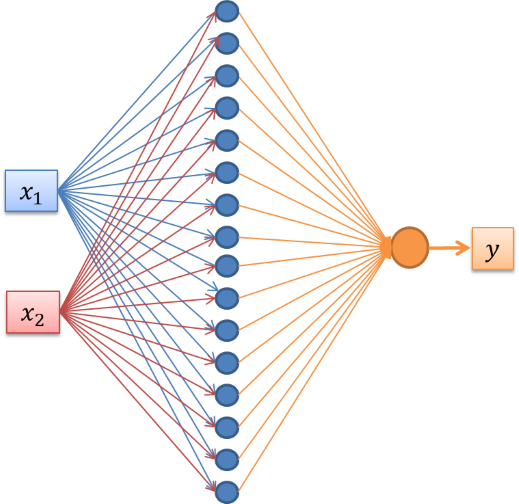

In [162]:
keras.backend.clear_session()
model = Sequential()
model.add(Dense(8, input_dim = 2, activation='relu'))
model.add(Dense(4, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (260.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

##Etapa 05
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/

In [163]:
#otimizador = keras.optimizers.Adam(learning_rate= 0.001)
#model.compile(optimizer= otimizador,
#              loss='binary_crossentropy',
#             metrics=['binary_accuracy'])

model.compile(optimizer= 'Adam',
             loss='binary_crossentropy',
             metrics=['binary_accuracy'])

##Etapa 06
Treinar o modelo e realizar a validação.

Epoch 1/100
4/4 - 1s - 318ms/step - binary_accuracy: 0.5000 - loss: 0.7294
Epoch 2/100
4/4 - 0s - 14ms/step - binary_accuracy: 0.5000 - loss: 0.7269
Epoch 3/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7250
Epoch 4/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7239
Epoch 5/100
4/4 - 0s - 14ms/step - binary_accuracy: 0.7500 - loss: 0.7229
Epoch 6/100
4/4 - 0s - 14ms/step - binary_accuracy: 0.7500 - loss: 0.7205
Epoch 7/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7191
Epoch 8/100
4/4 - 0s - 12ms/step - binary_accuracy: 0.7500 - loss: 0.7179
Epoch 9/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7163
Epoch 10/100
4/4 - 0s - 16ms/step - binary_accuracy: 0.7500 - loss: 0.7152
Epoch 11/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7138
Epoch 12/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7132
Epoch 13/100
4/4 - 0s - 13ms/step - binary_accuracy: 0.7500 - loss: 0.7109
Epoch 14/100
4/4 - 0s - 13ms/step

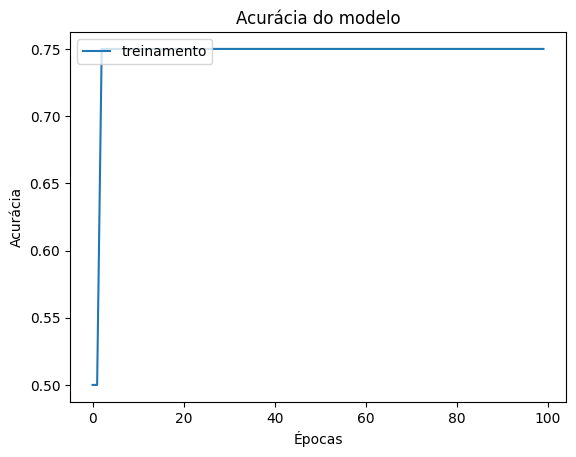

In [164]:
history = model.fit(x_train, y_train, epochs=100, batch_size=1, verbose=2)
plt.plot(history.history['binary_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Épocas')
plt.legend(['treinamento'], loc='upper left')
plt.show()

##Etapa 07
Realizar algumas predições.

In [165]:
y_pred = model.predict(x_train).round()

print ('x1 x2  y')
for i in range(4):
  print(x_train[i][0], x_train[i][1], y_pred[i])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
x1 x2  y
0 0 [0.]
0 1 [1.]
1 0 [1.]
1 1 [1.]


In [166]:
model.evaluate(x_train, y_train)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - binary_accuracy: 0.7500 - loss: 0.6123


[0.6122722625732422, 0.75]